In [1]:
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from decimal import Decimal, ROUND_CEILING

### Load reference

In [2]:
REF = [
    (
        "ProHD2_covariation",
        "Protein\nCo-abundance\n(Fischer\net al. 2025)",
    ),
    (
        "PROPER_share",
        "Multi-cell-line\nPROPER-seq\n(Johnson\net al. 2021)",
    ),
    (
        "PROPER_HEK293T",
        "HEK293T\nPROPER-seq\n(Johnson\net al. 2021)",
    ),
    (
        "ImageTop1",
        "HEK293T\nimage\n(Cho\net al. 2022)",
    ),
]

In [3]:
def load_reference_pairs(path):
    ref = pd.read_csv(path, sep="\t")
    ref_pair = []
    for row in ref.values:
        ref_pair.append(row[0] + "__" + row[1])
    return set(ref_pair)

In [4]:
ref_file_list, ref_label_list = map(list, zip(*REF))
ref_pair_list = [
    load_reference_pairs("../../result/reference/%s.txt" % name)
    for name in ref_file_list
]
n_ref = len(ref_file_list)

### Load PPIs and compute AUROC

In [5]:
PPI = [
    (
        "Intersect 50%",
        "../../result/HEK293T_HCT116_sample/intersect50/ppi/promergeclub_HCT116anchor_HEK293T.ppi.Percent1"
    ),
    (
        "Nonintersect 50%",
        "../../result/HEK293T_HCT116_sample/nonintersect50/ppi/promergeclub_HCT116anchor_HEK293T.ppi.Percent1"
    ),
    (
        "ProMERGE",
        "../../result/HEK293T_HCT116/ppi/promergeclub_HCT116anchor_HEK293T.ppi.Percent1"
    ),
]

In [6]:
label_list = [label for label, _ in PPI]
n_ppi = len(label_list)
promerge_idx = label_list.index("ProMERGE") # stat test compare to

In [7]:
score_dict = {}
label_dict = {}
auc_emb = np.empty((n_ppi, n_ref))

for ii, (label, name) in enumerate(PPI):
    ppi = pd.read_csv(name, sep="\t", header=None)
    
    score_dict[label] = ppi[1].values.astype(np.float64)
    label_dict[label] = [
        ppi[0].isin(ref_pair).astype(np.int8).values
        for ref_pair in ref_pair_list
    ]

    for rr in range(n_ref):
        auc_emb[ii, rr] = roc_auc_score(
            label_dict[label][rr], 
            score_dict[label]
        )

In [8]:
pd.DataFrame(auc_emb, index=label_list, columns=ref_file_list)

,ProHD2_covariation,PROPER_share,PROPER_HEK293T,ImageTop1
Intersect 50%,0.732721,0.618349,0.633434,0.781682
Nonintersect 50%,0.765975,0.656154,0.661895,0.815476
ProMERGE,0.771005,0.672734,0.681708,0.824666


### Bootstrap

In [9]:
def sort_by_score(score, label_mat, valid_mat):
    """
    Sort one method's units by score once and record where each block
    of tied scores starts.
    """
    order = np.argsort(score, kind="stable")
    score_sorted = score[order]
    grp_start = np.flatnonzero(
        np.r_[True, score_sorted[1:] != score_sorted[:-1]]
    )
    return label_mat[:, order], valid_mat[:, order], grp_start


def weighted_auroc(label_sorted, weight_sorted, grp_start):
    """
    AUROC in Mann-Whitney U form, each unit counted weight times and
    tied scores sharing half credit.
    """
    pos = weight_sorted * label_sorted
    neg = weight_sorted - pos
    pos_g = np.add.reduceat(pos, grp_start)
    neg_g = np.add.reduceat(neg, grp_start)
    below = np.cumsum(neg_g) - neg_g
    u = np.dot(pos_g, below + 0.5 * neg_g)
    return float(u / (pos_g.sum() * neg_g.sum()))


def bootstrap_auroc(label_sorted, valid_sorted, grp_start, n_boot, rng):
    """
    Resample one method's units with replacement and recompute its AUROC
    against every reference. Each method draws on its own.
    """
    n_ref, n_unit = label_sorted.shape
    auc = np.empty((n_boot, n_ref))
    for bb in tqdm(range(n_boot)):
        weight = np.bincount(
            rng.integers(0, n_unit, n_unit), minlength=n_unit
        ).astype(np.float64)
        for rr in range(n_ref):
            auc[bb, rr] = weighted_auroc(
                label_sorted[rr], weight * valid_sorted[rr], grp_start
            )
    return auc

In [10]:
N_BOOT = 10000
rng = np.random.default_rng(1)
auc_boot = np.empty((N_BOOT, len(label_list), n_ref))

for ii, label in enumerate(label_list):
    label_mat = np.vstack(label_dict[label])
    valid_mat = np.ones_like(label_mat)
    label_sorted, valid_sorted, group_start = sort_by_score(
        score_dict[label], label_mat, valid_mat
    )

    # check that unit weights reproduce roc_auc_score
    check = [
        weighted_auroc(
            label_sorted[rr],
            valid_sorted[rr].astype(np.float64),
            group_start,
        )
        for rr in range(n_ref)
    ]
    assert np.allclose(check, auc_emb[ii]), label

    auc_boot[:, ii, :] = bootstrap_auroc(
        label_sorted, valid_sorted, group_start, N_BOOT, rng
    )

100%|██████████| 10000/10000 [20:23<00:00,  8.17it/s]


In [11]:
# CI from bootstrap
ci_lo = np.percentile(auc_boot, 2.5, axis=0)
ci_hi = np.percentile(auc_boot, 97.5, axis=0)

# stat test from bootstrap, unpaired: each method has its own draws
stat_row_list = []
for rr, (ref_name, _) in enumerate(REF):
    for mm, method_label in enumerate(label_list):
        
        boot_a = auc_boot[:, mm, rr]
        boot_b = auc_boot[:, promerge_idx, rr]
        delta_boot = boot_a - boot_b
        delta_obs = auc_emb[mm, rr] - auc_emb[promerge_idx, rr]

        p_lower = (np.sum(delta_boot >= 0) + 1) / (N_BOOT + 1)
        p_upper = (np.sum(delta_boot <= 0) + 1) / (N_BOOT + 1)

        se_delta = np.hypot(boot_a.std(ddof=1), boot_b.std(ddof=1))
        z = delta_obs / se_delta
        
        stat_row_list.append({
            "reference": ref_name,
            "method": method_label,
            "auc": auc_emb[mm, rr],
            "n_boot": N_BOOT,
            "ci_lower": ci_lo[mm, rr],
            "ci_upper": ci_hi[mm, rr],
            "delta_auc": delta_obs,
            "p_boot": min(2 * min(p_lower, p_upper), 1.0),
            "z": z,
            "p_z": 2 * norm.sf(abs(z)),
        })
stat_df = pd.DataFrame(stat_row_list)
stat_df.to_csv("./figS18_benchmark_pair_sample.tsv", sep="\t", index=False)

### plot

In [12]:
# p-value annotation: 2 decimal places, always rounded up
def format_p_z(p):
    value = Decimal(str(p))
    if value.is_nan():
        return "nan"
    if value == 0:
        return "0.00e0"

    exponent = value.adjusted()
    mantissa = value.scaleb(-exponent).quantize(
        Decimal("0.01"), rounding=ROUND_CEILING
    )
    if mantissa == Decimal("10.00"):
        mantissa = Decimal("1.00")
        exponent += 1
    return f"{mantissa:.2f}e{exponent}"

pz_lookup = {
    (row["reference"], row["method"]): format_p_z(row["p_z"])
    for _, row in stat_df.iterrows()
}

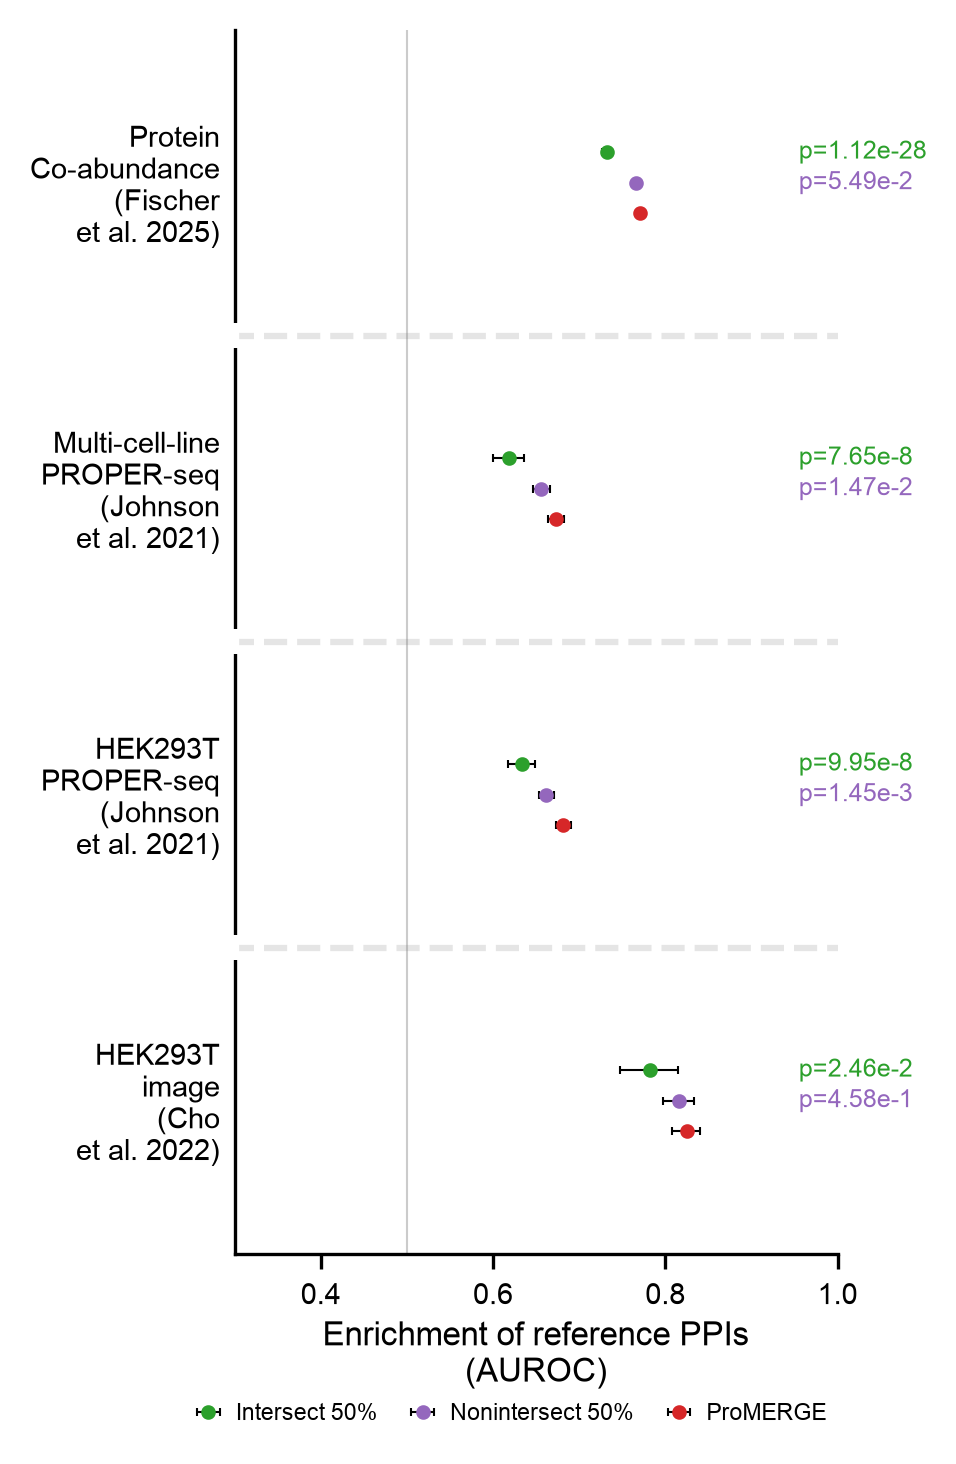

In [13]:
color_list = [
    "tab:green", "tab:purple",
    "tab:red",
]
marker_list = [
    "o", "o",
    "o"
]

row_span = (n_ppi - 1) * 0.1
row_y = np.arange(n_ref, 0, -1)
method_dy = row_span - np.arange(n_ppi) * 0.1
pad = (1 - row_span) / 2

# init plot
plt.style.use("/home/jig049/misc/style.mplstyle")
fig, ax = plt.subplots(figsize=(3, 5.1), dpi=300)
fig.subplots_adjust(left=0.30, right=0.97, bottom=0.19, top=0.99)

# main plot
for ii, method_label in enumerate(label_list):
    y = row_y + method_dy[ii]
    ax.errorbar(
        y=y,
        x=auc_emb[ii],
        xerr=np.vstack([
            auc_emb[ii] - ci_lo[ii],
            ci_hi[ii] - auc_emb[ii]
        ]),
        color=color_list[ii],
        marker=marker_list[ii],
        linestyle="",
        ms=2.5,
        ecolor="black",
        barsabove=False,
        elinewidth=0.5,
        capsize=1,
        capthick=0.5,
        label=method_label,
    )
    
    # p_z annotation
    if ii == promerge_idx:
        continue
    for rr, ref_file in enumerate(ref_file_list):
        ax.text(
            0.955,
            y[rr],
            "p="+pz_lookup[(ref_file, method_label)],
            fontsize=6,
            va="center",
            ha="left",
            color=color_list[ii],
        )

# line for AUROC=0.5
ax.vlines(
    0.5,
    ymin=0,
    ymax=n_ref + 1,
    linestyles="-",
    color="tab:grey",
    alpha=0.4,
    lw=0.5,
)

# axis and tick
ax.set_xlim([0.3, 1])
ax.set_ylim([row_y[-1] - pad, row_y[0] + row_span + pad])
ax.set_xticks([0.4, 0.6, 0.8, 1.0])
ax.set_yticks(row_y + row_span / 2, labels=ref_label_list, fontsize=8)
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", labelsize=7, length=0)
ax.set_xlabel("Enrichment of reference PPIs\n(AUROC)", labelpad=2, fontsize=8)
ax.spines[["right", "top"]].set_visible(False)

# horizontal line and white gap in y-axis to separate group
sep_y = row_y[:-1] - pad
ax.hlines(sep_y, xmin=0, xmax=1, linestyles="--", color="tab:grey", alpha=0.2)
trans = ax.get_yaxis_transform()
gap = 0.08
for yy in sep_y:
    ax.plot(
        [0, 0],
        [yy - gap / 2, yy + gap / 2],
        transform=trans,
        color="white",
        lw=2.0,
        solid_capstyle="butt",
        clip_on=False,
        zorder=10,
    )

# legene
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.45, -0.105),
    ncol=3,
    fontsize=5.5,
    frameon=False,
    handletextpad=0.2,
    columnspacing=1.0,
    labelspacing=0.3,
)

plt.savefig("./figS20_benchmark_pair_sample.pdf", bbox_inches="tight", transparent=True)